# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

--2026-11-06 22:19:14--  https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58374 (57K) [text/plain]
Saving to: ‘car_data.csv.3’

car_data.csv.3      100%[===================>]  57.01K  --.-KB/s    in 0.01s   

2026-11-06 22:19:15 (4.38 MB/s) - ‘car_data.csv.3’ saved [58374/58374]



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [4]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,581,89,36,68,141,59,8,139,47,18,130,166,291,127,73,7,1,189,196
1,545,88,44,84,135,55,12,155,44,20,158,176,351,164,75,7,11,183,195
2,680,95,46,76,162,66,11,162,42,20,155,175,381,172,74,8,4,184,193
3,374,87,36,53,117,58,4,118,57,17,125,138,205,138,85,9,15,180,183
4,459,98,42,90,192,61,9,178,37,21,144,189,480,138,61,3,8,199,208
5,595,89,50,83,195,65,6,178,37,21,156,207,481,210,71,1,6,189,194
6,532,104,49,105,209,61,11,207,32,24,157,217,637,168,64,0,19,193,207
7,56,97,44,96,195,63,9,185,36,22,144,202,512,165,66,4,8,191,199
8,722,94,45,85,163,68,10,157,44,20,156,170,357,176,73,17,11,187,195
9,699,93,47,83,165,60,7,167,40,20,147,197,417,201,73,12,4,187,192


Methods `describe` and `info` deliver some useful information.

In [5]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,422.781421,93.832423,45.107468,82.320583,168.816029,61.504554,8.630237,169.666667,40.810565,20.652095,148.604736,189.102004,444.544627,175.959927,72.608379,6.367942,12.420765,188.770492,195.497268
std,243.179298,8.466829,6.206992,16.056218,34.187397,8.029739,4.628131,33.849333,7.978792,2.626559,14.714759,31.920930,179.678576,32.283052,7.563937,4.835935,9.013555,6.149459,7.424959
min,1.000000,73.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,220.000000,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,147.000000,33.000000,19.000000,138.000000,167.000000,318.000000,151.000000,68.000000,2.000000,5.000000,184.000000,190.000000
50%,425.000000,93.000000,45.000000,80.000000,166.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,179.000000,366.000000,174.000000,72.000000,5.000000,11.000000,188.000000,196.000000
75%,627.000000,100.000000,50.000000,98.000000,197.000000,65.000000,10.000000,201.000000,46.000000,23.000000,160.000000,217.000000,602.000000,200.000000,76.000000,9.000000,18.000000,193.000000,201.000000
max,845.000000,119.000000,59.000000,112.000000,333.000000,138.000000,55.000000,262.000000,59.000000,28.000000,188.000000,320.000000,998.000000,268.000000,135.000000,22.000000,41.000000,203.000000,211.000000


In [6]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [7]:
### YOUR CODE HERE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35, random_state=9, stratify=target)


X_train = X_train[:, 1:]
X_test  = X_test[:, 1:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape) # должно быть: (549, 18)
print("X_test_scaled shape: ", X_test_scaled.shape)  # должно быть: (297, 18)

# car_data.csv загружал вручную в /content

X_train_scaled shape: (549, 18)
X_test_scaled shape:  (297, 18)


**Объяснение**

Первый столбец - это порядковый номер, а не признак. Он не несет информации о классе и только добавляет шум. Удаляю его из X_train и X_test.
Признаки имеют разный масштаб. Модели, основанные на расстояниях или градиентном спуске, будут некорректно работать без нормализации. StandardScaler приводит все признаки к нулевому среднему и единичной дисперсии.
fit_transform вызывается только на X_train, а transform на X_test. Это предотвращает утечку данных.

Зафиксировал random_state, чтобы результаты не менялись между запусками.


#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

Best C: {'C': 100}
Accuracy: 0.8181818181818182
F1 macro: 0.8189617174137563


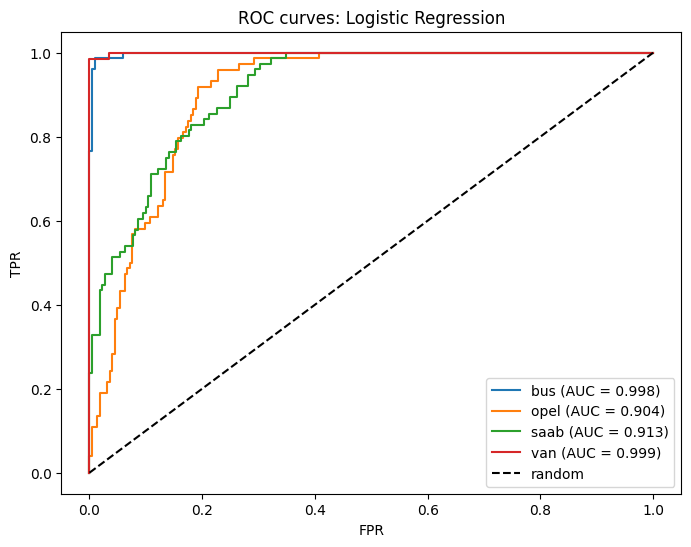

In [8]:
### YOUR CODE HERE

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

lr = LogisticRegression(multi_class='multinomial', solver='saga', tol=1e-3, max_iter=500)

params = {'C': [0.01, 0.1, 1, 10, 100]}
gs = GridSearchCV(lr, params, cv=5, scoring='f1_macro')
gs.fit(X_train_scaled, y_train)

print("Best C:", gs.best_params_)
best_lr = gs.best_estimator_

y_pred = best_lr.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 macro:", f1_score(y_test, y_pred, average='macro'))

y_proba = best_lr.predict_proba(X_test_scaled)
classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8, 6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='random')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curves: Logistic Regression')
plt.legend()
plt.show()

In [9]:
# You might use this command to install scikit-plot.
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding
# virtual environment instead

# ! pip install scikit-plot

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

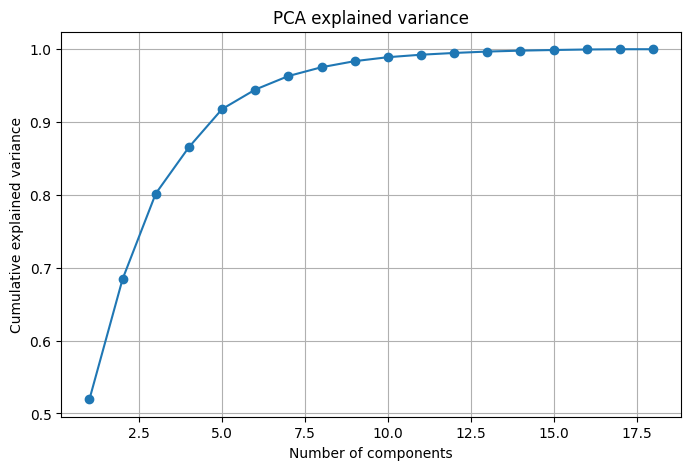

90% variance: 5 components
95% variance: 7 components
99% variance: 11 components


In [10]:
### YOUR CODE HERE

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

pca = PCA()
pca.fit(X_train_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA explained variance')
plt.grid()
plt.show()

for thr in [0.90, 0.95, 0.99]:
    n = np.argmax(cumulative >= thr) + 1
    print(f"{int(thr*100)}% variance: {n} components")

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [11]:
### YOUR CODE HERE

from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=0.99)
pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("PCA components:", pca.n_components_)
print("Explained variance:", pca.explained_variance_ratio_.sum())

print("X_train_pca shape:", X_train_pca.shape)
print("X_test_pca shape: ", X_test_pca.shape)

Original features: 18
PCA components: 11
Explained variance: 0.9924551389544523
X_train_pca shape: (549, 11)
X_test_pca shape:  (297, 11)


**Объяснение**

График (2.2) показывает, что первые несколько компонент содержат основную часть информации: ~90% дисперсии объясняется первыми 5 компонентами и ~95% дисперсии объясняется первыми 7 компонентами.
После примерно 10-й компоненты оставшиеся признаки практически не вносят вклада.

Сначала я выбрал 7 компонент (сохранит практически всю информацию и существенно снизит размерность с 18 до 7 признаков).
Но для данного набора данных точность упала с 0,82 до 0,61 (в блоке 2.4).
Поэтому в качестве компромисса я выбрал 99% (11 компонент).

Нормализвция обязательна, так как исходные признаки имеют сильно различающиеся масштабы. Без нормализации метод PCA был бы полностью "подавлен" признаками с высокой дисперсией, а остальные признаки были бы фактически проигнорированы.
PCA применялся к стандартизированным данным (`X_train_scaled`), а не к исходным признакам.

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

Best C (PCA): {'C': 10}
Accuracy (PCA): 0.7239057239057239
F1 macro (PCA): 0.7255000945076153


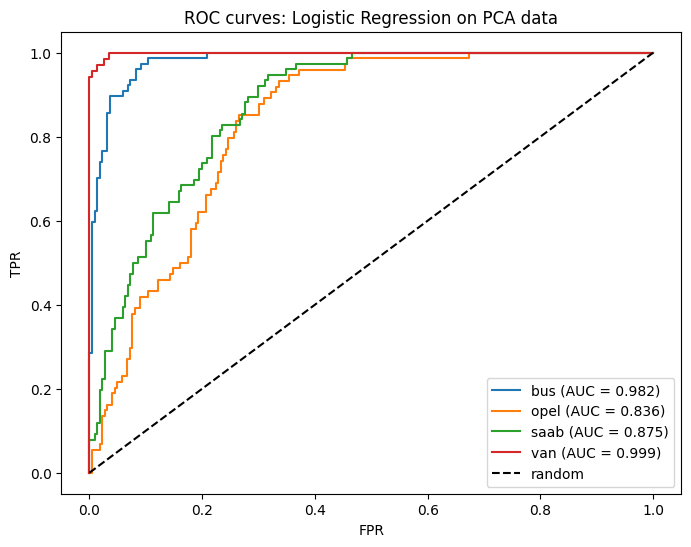

In [12]:
### YOUR CODE HERE

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

lr_pca = LogisticRegression(multi_class='multinomial', solver='saga', tol=1e-3, max_iter=500)

params = {'C': [0.01, 0.1, 1, 10, 100]}
gs_pca = GridSearchCV(lr_pca, params, cv=5, scoring='f1_macro')
gs_pca.fit(X_train_pca, y_train)

print("Best C (PCA):", gs_pca.best_params_)
best_lr_pca = gs_pca.best_estimator_

y_pred_pca = best_lr_pca.predict(X_test_pca)
print("Accuracy (PCA):", accuracy_score(y_test, y_pred_pca))
print("F1 macro (PCA):", f1_score(y_test, y_pred_pca, average='macro'))

y_proba_pca = best_lr_pca.predict_proba(X_test_pca)
classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8, 6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_pca[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='random')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curves: Logistic Regression on PCA data')
plt.legend()
plt.show()

**Объяснение**

Сравнение LR и LR на PCA данных:

| Model | Accuracy | F1 macro |
|-------|----------|----------|
| Basic LR (2.1) | 0.82 | 0.82 |
| LR PCA data [11 components] (2.4) | 0.72 | 0.73 |
| LR PCA data [7 components] (2.4) | 0.61 | 0.61 |

Применение PCA позволило сократить размерность данных с 18 до 11 признаков (уменьшение на 38%), точность при этом снизилась с ~ 0.82 до 0.72.

Это значит, что информация необходимая для классификации распределена по компонентам обладающими небольшой дисперсией.
Поэтому при сохранении 95% дисперсии (7 компонент) точность составила 0.61, а при 99% (11 компонент) — поднялась до 0.72

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [13]:
from sklearn.tree import DecisionTreeClassifier

# YOUR CODE HERE
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

dt = DecisionTreeClassifier(random_state=13)

params = {'max_depth': range(2, 21)}
gs_dt = GridSearchCV(dt, params, cv=5, scoring='f1_macro')
gs_dt.fit(X_train, y_train)

print("Best max_depth:", gs_dt.best_params_)
best_dt = gs_dt.best_estimator_

y_pred_dt = best_dt.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("F1 macro:", f1_score(y_test, y_pred_dt, average='macro'))

Best max_depth: {'max_depth': 13}
Accuracy: 0.7171717171717171
F1 macro: 0.7193680772141333


**Объяснение**

Оптимальное значение max_depth: 13 (определено с помощью 5-блочной кросс-валидации, метрика - f1_macro)

Точность на тестовой выборке: 0,717

F1-мера на тестовой выборке: 0,719

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

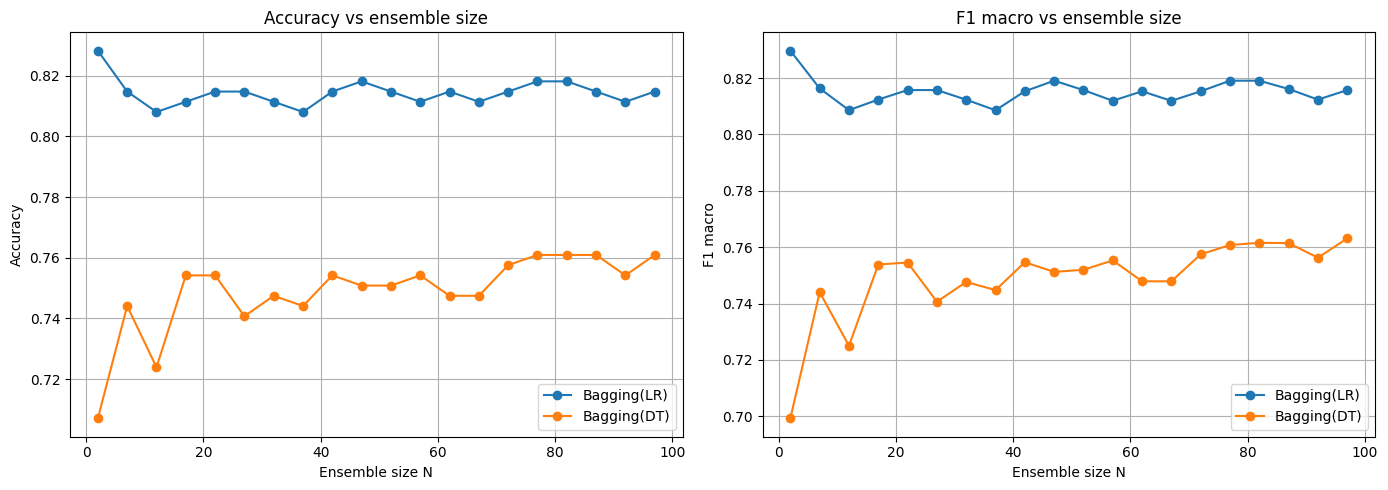

LR bagging (N=100): acc=0.8148, f1=0.8157
DT bagging (N=100): acc=0.7609, f1=0.7631


In [14]:
# YOUR CODE HERE

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

np.random.seed(13)

def bagging_experiment(model_factory, X_tr, y_tr, X_te, y_te, n_max=100, sizes=range(2, 101, 5)):
    """Build N-model bagging ensembles, return accuracy/f1 vs N."""
    n = len(X_tr)

    boot_idx = [np.random.choice(n, n, replace=True) for _ in range(n_max)]

    models = [model_factory().fit(X_tr[i], y_tr[i]) for i in boot_idx]
    classes = models[0].classes_

    results = []
    for N in sizes:
        proba = np.mean([m.predict_proba(X_te) for m in models[:N]], axis=0)
        pred = classes[np.argmax(proba, axis=1)]
        results.append((N, accuracy_score(y_te, pred), f1_score(y_te, pred, average='macro')))
    return results

res_lr = bagging_experiment(lambda: LogisticRegression(C=gs.best_params_['C'], multi_class='multinomial', solver='saga', tol=1e-3, max_iter=500), X_train_scaled, y_train, X_test_scaled, y_test)
res_dt = bagging_experiment(lambda: DecisionTreeClassifier(max_depth=gs_dt.best_params_['max_depth']), X_train, y_train, X_test, y_test)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for res, name in [(res_lr, 'Bagging(LR)'), (res_dt, 'Bagging(DT)')]:
    ns   = [r[0] for r in res]
    accs = [r[1] for r in res]
    f1s  = [r[2] for r in res]
    ax[0].plot(ns, accs, marker='o', label=name)
    ax[1].plot(ns, f1s,  marker='o', label=name)

ax[0].set_xlabel('Ensemble size N'); ax[0].set_ylabel('Accuracy')
ax[0].set_title('Accuracy vs ensemble size'); ax[0].legend(); ax[0].grid()
ax[1].set_xlabel('Ensemble size N'); ax[1].set_ylabel('F1 macro')
ax[1].set_title('F1 macro vs ensemble size'); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

print(f"LR bagging (N=100): acc={res_lr[-1][1]:.4f}, f1={res_lr[-1][2]:.4f}")
print(f"DT bagging (N=100): acc={res_dt[-1][1]:.4f}, f1={res_dt[-1][2]:.4f}")

**Объяснение**

График Bagging(LR) выглядит как прямая линия, логистическая регрессия - это "устойчивая" модель (с низкой дисперсией). Небольшие изменения в обучающей выборке практически не влияют на положение разделяющей гиперплоскости, поэтому использование бэггинга для таких моделей не дает преимуществ.

Дерево решений — "неустойчивая" модель (с высокой дисперсией). Отдельное дерево склонно к переобучению, а усреднение результатов множества деревьев позволяет снизить дисперсию - отсюда и наблюдаемый прирост в точности (примерно 0.76 против 0.72).

Оптимальное количество моделей примерно 20–30. Дальнейшее увеличение их числа дает незначительный прирост точности, при этом время получения прогноза растет линейно.

Гиперпараметры, подобранные в 2.5, не являются оптимальными для деревьев в составе ансамбля.
В 2.5 с помощью кросс-валидации (CV) было выбрано значение max_depth=13, что позволило найти баланс между смещением и дисперсией для одного дерева. В Bagging дисперсия уже снижается за счет усреднения, поэтому можно использовать более глубокие деревья чтобы уменьшить смещение.
Но обычный бэггинг упирается в "потолок" т.к. деревья сильно коррелируют друг с другом (все они используют одни и те же наиболее значимые признаки для построения верхних узлов).

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

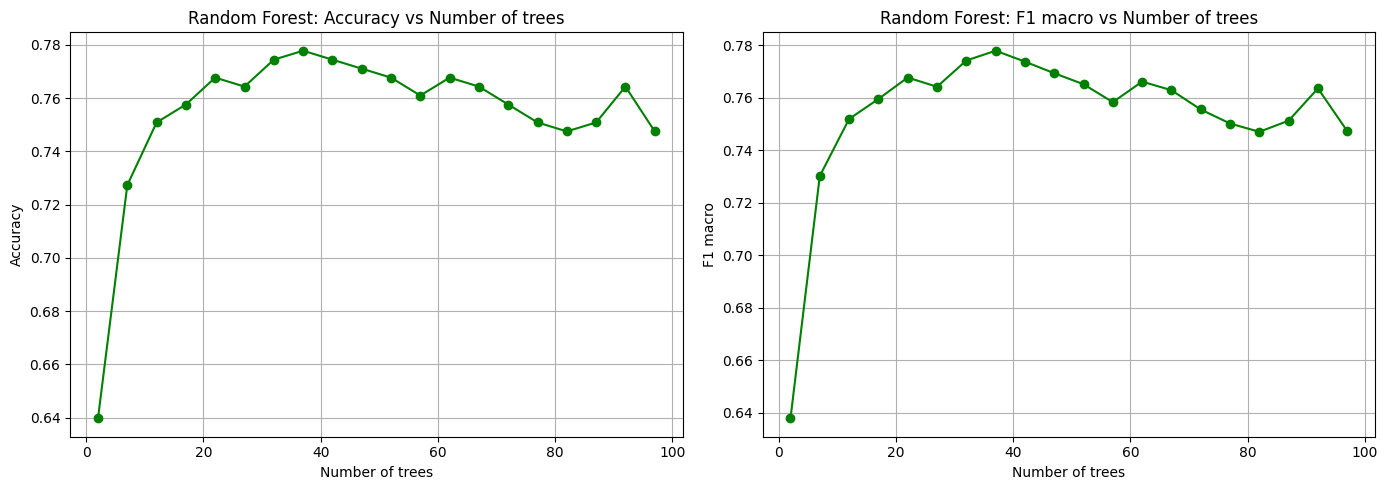

RF (N=100): acc=0.7475, f1=0.7473


In [15]:
from sklearn.ensemble import RandomForestClassifier
# YOUR CODE HERE
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

rf_acc = []
rf_f1 = []
n_trees_range = range(2, 101, 5)

for n in n_trees_range:
    rf = RandomForestClassifier(n_estimators=n, random_state=13, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_test)
    rf_acc.append(accuracy_score(y_test, y_pred))
    rf_f1.append(f1_score(y_test, y_pred, average='macro'))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(n_trees_range, rf_acc, marker='o', color='green')
plt.xlabel('Number of trees'); plt.ylabel('Accuracy')
plt.title('Random Forest: Accuracy vs Number of trees'); plt.grid()

plt.subplot(1, 2, 2)
plt.plot(n_trees_range, rf_f1, marker='o', color='green')
plt.xlabel('Number of trees'); plt.ylabel('F1 macro')
plt.title('Random Forest: F1 macro vs Number of trees'); plt.grid()
plt.tight_layout(); plt.show()

print(f"RF (N=100): acc={rf_acc[-1]:.4f}, f1={rf_f1[-1]:.4f}")

**Объяснение**

Оптимальное значение составляет примерно 25–30 деревьев.
Дальнейшее увеличение их числа дает незначительный прирост точности, при этом время получения прогноза растет линейно.

В 2.6 при использовании бэггинга на  деревьях точность достигала плато на уровне ~ 0,76. Случайный лес показывает схожий результат (~ 0,75) благодаря подвыборке признаков.

В бэггинге для построения верхних узлов деревья всегда используют одни и те же наиболее значимые признаки. Усреднение таких коррелированных деревьев не позволяет существенно снизить дисперсию модели.
В случайном лесе для каждого разбиения выбирается случайное подмножество признаков. Это устраняет корреляцию между деревьями и значительно уменьшает дисперсию ансамбля.

Но на этих данных выигрыша нет, а разница в точности на тесте лежит в пределах шума.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

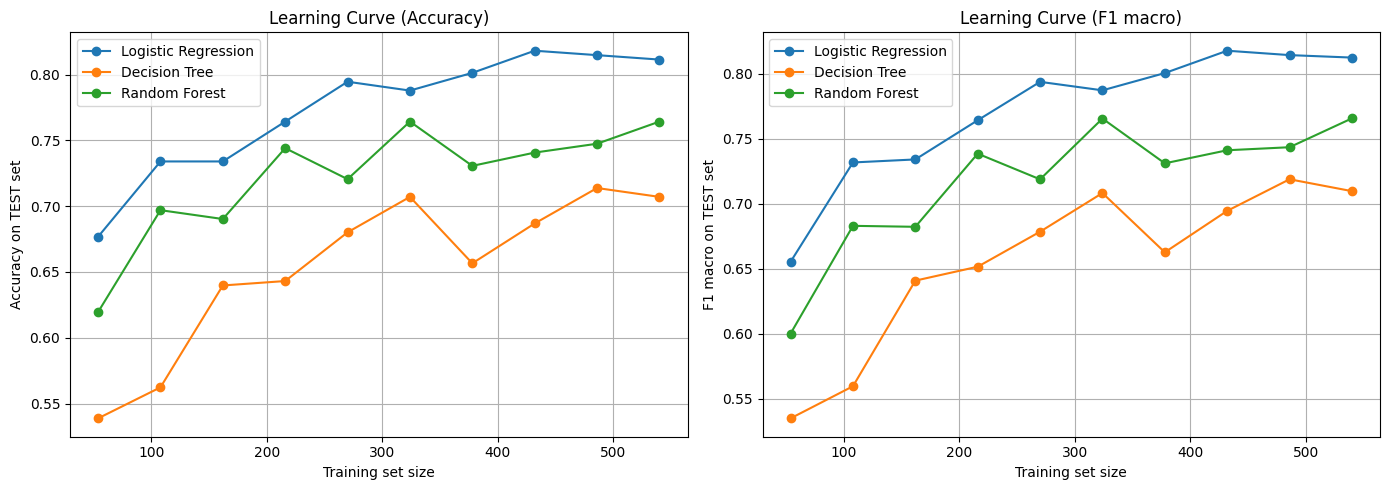

In [16]:
# YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils import shuffle

X_train_shuffled, y_train_shuffled = shuffle(X_train, y_train, random_state=13)
X_train_scaled_shuffled, _ = shuffle(X_train_scaled, y_train, random_state=13)

chunk_size = len(X_train) // 10

train_sizes = []
lr_acc, dt_acc, rf_acc = [], [], []
lr_f1, dt_f1, rf_f1 = [], [], []

for i in range(1, 11):
    size = i * chunk_size

    X_sub = X_train_shuffled[:size]
    y_sub = y_train_shuffled[:size]
    X_sub_scaled = X_train_scaled_shuffled[:size]

    train_sizes.append(size)

    best_lr.fit(X_sub_scaled, y_sub)
    y_pred_lr = best_lr.predict(X_test_scaled)
    lr_acc.append(accuracy_score(y_test, y_pred_lr))
    lr_f1.append(f1_score(y_test, y_pred_lr, average='macro'))

    best_dt.fit(X_sub, y_sub)
    y_pred_dt = best_dt.predict(X_test)
    dt_acc.append(accuracy_score(y_test, y_pred_dt))
    dt_f1.append(f1_score(y_test, y_pred_dt, average='macro'))

    from sklearn.ensemble import RandomForestClassifier
    rf = RandomForestClassifier(n_estimators=30, random_state=13, n_jobs=-1)
    rf.fit(X_sub, y_sub)
    y_pred_rf = rf.predict(X_test)
    rf_acc.append(accuracy_score(y_test, y_pred_rf))
    rf_f1.append(f1_score(y_test, y_pred_rf, average='macro'))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(train_sizes, lr_acc, marker='o', label='Logistic Regression')
plt.plot(train_sizes, dt_acc, marker='o', label='Decision Tree')
plt.plot(train_sizes, rf_acc, marker='o', label='Random Forest')
plt.xlabel('Training set size')
plt.ylabel('Accuracy on TEST set')
plt.title('Learning Curve (Accuracy)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_sizes, lr_f1, marker='o', label='Logistic Regression')
plt.plot(train_sizes, dt_f1, marker='o', label='Decision Tree')
plt.plot(train_sizes, rf_f1, marker='o', label='Random Forest')
plt.xlabel('Training set size')
plt.ylabel('F1 macro on TEST set')
plt.title('Learning Curve (F1 macro)')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

**Объяснение**

- Логистическая регрессия хорошо подходит для очень маленьких наборов данных. Но для нее характерно высокое смещение (недообучение). Т.к. модель строит линейную границу принятия решений, она извлекает максимум возможной информации из небольшого набора данных, но дальнейшее увеличение объема данных не помогает преодолеть фундаментальное ограничение, связанное с линейностью (кривая выходит на плато).

- Отдельное дерево решений - модель нестабильная и неэффективная. Она обладает высоким разбросом (переобучение)- на небольших подмножествах данных оно склонно "запоминать" шум. Модель требовательна к объему данных - при наличии 500+ примеров она остается наименее эффективной, а что бы кривая вышла на плато нужно еще больше данных.

- Случайный лес - показывает неплохие результаты при любом объеме данных, приближаясь к пределу эффективности линейной модели. Благодаря усреднению результатов модель эффективно снижает высокий разброс, свойственный отдельному дереву решений. На малых выборках он проигрывает логистической регрессии из-за нестабильности деревьев, но по мере роста данных плавно растет и почти достигает уровня линейной модели (~ 0.77).


#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [17]:
# YOUR CODE HERE
!pip install lightgbm

Training until validation scores don't improve for 20 rounds
[50]	train's multi_logloss: 0.058523	valid's multi_logloss: 0.607389
Early stopping, best iteration is:
[35]	train's multi_logloss: 0.13083	valid's multi_logloss: 0.577729

Optimal number of trees (best iteration): 35
Accuracy: 0.7643
F1 macro: 0.7671


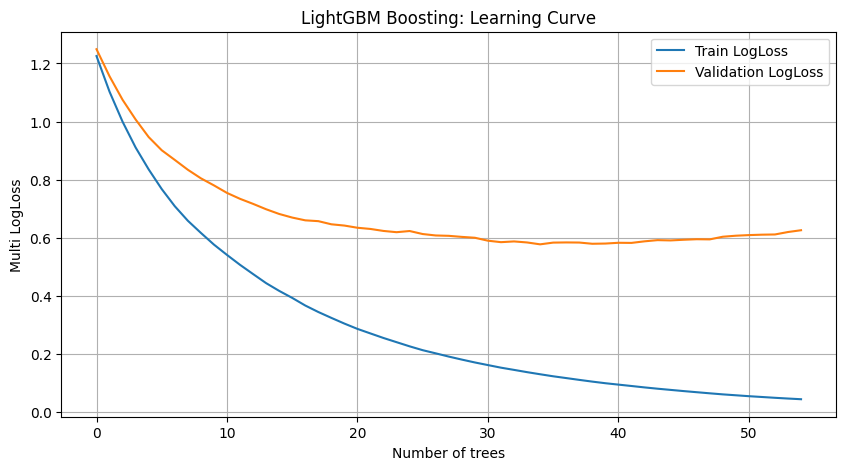

In [18]:
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train_enc, test_size=0.2, random_state=13, stratify=y_train_enc
)

train_data = lgb.Dataset(X_tr, label=y_tr)
val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

params = {'objective': 'multiclass','num_class': 4,'metric': 'multi_logloss','verbosity': -1,'seed': 13,'learning_rate': 0.1}
evals_result = {}
bst = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[train_data, val_data],
    valid_names=['train', 'valid'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=20),
        lgb.log_evaluation(period=50),
        lgb.record_evaluation(evals_result)
    ]
)

print(f"\nOptimal number of trees (best iteration): {bst.best_iteration}")

y_pred_proba = bst.predict(X_test, num_iteration=bst.best_iteration)
y_pred = np.argmax(y_pred_proba, axis=1)

print(f"Accuracy: {accuracy_score(y_test_enc, y_pred):.4f}")
print(f"F1 macro: {f1_score(y_test_enc, y_pred, average='macro'):.4f}")

plt.figure(figsize=(10, 5))
plt.plot(evals_result['train']['multi_logloss'], label='Train LogLoss')
plt.plot(evals_result['valid']['multi_logloss'], label='Validation LogLoss')
plt.ylabel('Multi LogLoss')
plt.xlabel('Number of trees')
plt.title('LightGBM Boosting: Learning Curve')
plt.legend()
plt.grid()
plt.show()

**Объяснение**

Оптимальное количество деревьев 35 (определено ранней остановкой).

Для ранней остановки я выделил 20% обучающей выборки под валидацию, чтобы тестовая выборка не участвовала в подборе числа деревьев. Тест использовался только для итоговой оценки.

В качестве метрики для остановки взял multi_logloss, а не долю ошибок. При multi_error остановка срабатывала уже на 3 деревьях, и модель оставалась недообученной.